In [3]:
import pandas as pd
import numpy as np
import sklearn

print("Everything working!")

Everything working!


In [4]:
import pandas as pd

df2 = pd.read_csv("../data/data.csv")

df2.head()

,segment_id,city_name,admin_ward,latitude,longitude,catchment_id,elevation_m,dem_source,land_use,soil_group,drainage_density_km_per_km2,storm_drain_proximity_m,storm_drain_type,rainfall_source,historical_rainfall_intensity_mm_hr,return_period_years,risk_labels
0,SEG-00001,"Colombo, Sri Lanka",Borough East,6.920633,79.912600,CAT-136,NaN,Copernicus_EEA-10_v5,Institutional,NaN,4.27,160.5,CurbInlet,ERA5,39.4,50,monitor
1,SEG-00002,"Chennai, India",Ward D,13.076487,80.281774,CAT-049,-2.19,Copernicus_EEA-10_v5,Residential,D,7.54,NaN,OpenChannel,ERA5,56.8,25,ponding_hotspot|low_lying|event_2025-05-02
2,SEG-00003,"Ahmedabad, India",Sector 12,23.019473,72.638578,CAT-023,30.88,SRTM_3arc,Industrial,B,11.00,152.5,OpenChannel,IMD,16.3,5,monitor
3,SEG-00004,"Hong Kong, China",Sector 14,22.302602,114.078673,CAT-168,24.28,SRTM_3arc,Residential,B,7.32,37.0,Manhole,ERA5,77.0,10,monitor
4,SEG-00005,"Durban, South Africa",Sector 5,-29.887602,30.911008,CAT-171,35.70,SRTM_3arc,Industrial,C,4.50,292.4,OpenChannel,ERA5,20.8,5,monitor


In [5]:
 df.shape


NameError: name 'df' is not defined

In [6]:
df.columns

NameError: name 'df' is not defined

In [7]:
df.info()


NameError: name 'df' is not defined

In [8]:
df.isnull().sum()

NameError: name 'df' is not defined

In [9]:
df.duplicated().sum()

NameError: name 'df' is not defined

In [10]:
df.describe()

NameError: name 'df' is not defined

In [11]:
print(df["Soil Type"].value_counts())

NameError: name 'df' is not defined

In [12]:
df.groupby("Flood Occurred")["Rainfall (mm)"].mean()

NameError: name 'df' is not defined

In [13]:
df.groupby("Flood Occurred")["Water Level (m)"].mean()

NameError: name 'df' is not defined

In [14]:
df.groupby("Flood Occurred")["River Discharge (m³/s)"].mean()

NameError: name 'df' is not defined

In [15]:
df.groupby("Flood Occurred").mean(numeric_only=True).T

NameError: name 'df' is not defined

In [16]:
df.select_dtypes(include="number").corr()["Flood Occurred"].sort_values(ascending=False)

NameError: name 'df' is not defined

In [17]:
pd.crosstab(df["Land Cover"], df["Flood Occurred"], normalize="index") * 100

NameError: name 'df' is not defined

In [18]:
pd.crosstab(df["Soil Type"], df["Flood Occurred"], normalize="index") * 100

NameError: name 'df' is not defined

In [19]:
df2["risk_labels"].value_counts()

risk_labels
monitor                                            1991
low_lying                                           386
extreme_rain_history                                137
sparse_drainage                                      88
ponding_hotspot|low_lying                            78
                                                   ... 
ponding_hotspot|low_lying|event_2023-06-21            1
ponding_hotspot|low_lying|event_2022-06-14            1
extreme_rain_history|low_lying|event_2025-04-14       1
low_lying|event_2022-06-11                            1
extreme_rain_history|low_lying|event_2023-11-07       1
Name: count, Length: 195, dtype: int64

In [20]:
df2["city_name"].value_counts()

city_name
Manila, Philippines    61
San Francisco, USA     60
Philadelphia, USA      59
Seoul, South Korea     58
Athens, Greece         58
                       ..
Hamburg, Germany       37
Bangkok, Thailand      35
Hong Kong, China       34
Colombo, Sri Lanka     30
London, UK             29
Name: count, Length: 63, dtype: int64

In [21]:
df2["land_use"].value_counts()

land_use
Residential      827
Roads            599
Commercial       493
Green            359
Industrial       357
Mixed            110
Institutional    106
Water             83
Informal          29
Name: count, dtype: int64

In [22]:
# Show the most common risk labels
df2["risk_labels"].value_counts().head(30)

risk_labels
monitor                                                            1991
low_lying                                                           386
extreme_rain_history                                                137
sparse_drainage                                                      88
ponding_hotspot|low_lying                                            78
ponding_hotspot|extreme_rain_history|low_lying                       39
low_lying|sparse_drainage                                            21
extreme_rain_history|low_lying                                       11
ponding_hotspot|extreme_rain_history                                  8
extreme_rain_history|sparse_drainage                                  6
ponding_hotspot|low_lying|sparse_drainage                             6
ponding_hotspot|low_lying|event_2024-07-26                            2
ponding_hotspot                                                       2
ponding_hotspot|low_lying|event_2024-08-19          

In [23]:
# Check missing values
df2.isnull().sum()

segment_id                               0
city_name                                0
admin_ward                               0
latitude                                 0
longitude                                0
catchment_id                             0
elevation_m                            161
dem_source                               0
land_use                                 0
soil_group                             362
drainage_density_km_per_km2            284
storm_drain_proximity_m                239
storm_drain_type                       178
rainfall_source                        315
historical_rainfall_intensity_mm_hr      0
return_period_years                      0
risk_labels                              0
dtype: int64

In [24]:
# See all columns
df2.columns

Index(['segment_id', 'city_name', 'admin_ward', 'latitude', 'longitude',
       'catchment_id', 'elevation_m', 'dem_source', 'land_use', 'soil_group',
       'drainage_density_km_per_km2', 'storm_drain_proximity_m',
       'storm_drain_type', 'rainfall_source',
       'historical_rainfall_intensity_mm_hr', 'return_period_years',
       'risk_labels'],
      dtype='object')

In [25]:
def get_main_risk(label):
    if "ponding_hotspot" in label:
        return "Ponding Hotspot"
    elif "extreme_rain_history" in label:
        return "Extreme Rain"
    elif "sparse_drainage" in label:
        return "Sparse Drainage"
    elif "low_lying" in label:
        return "Low Lying"
    else:
        return "Monitor"

df2["main_risk"] = df2["risk_labels"].apply(get_main_risk)

In [26]:
df2["main_risk"].value_counts()

main_risk
Monitor            1994
Low Lying           417
Ponding Hotspot     222
Extreme Rain        173
Sparse Drainage     157
Name: count, dtype: int64

In [27]:
df2.groupby("main_risk")[[
    "elevation_m",
    "drainage_density_km_per_km2",
    "storm_drain_proximity_m",
    "historical_rainfall_intensity_mm_hr",
    "return_period_years"
]].mean()

,elevation_m,drainage_density_km_per_km2,storm_drain_proximity_m,historical_rainfall_intensity_mm_hr,return_period_years
main_risk,,,,,
Extreme Rain,29.730886,6.405157,131.541935,100.336994,38.057803
Low Lying,1.679161,6.978859,135.415957,37.670504,16.491607
Monitor,50.435487,6.528674,118.691961,37.450100,18.457372
Ponding Hotspot,0.439087,5.812450,109.870335,72.193694,27.175676
Sparse Drainage,42.743841,2.453057,159.598601,38.496178,13.770701


In [28]:
def assign_risk(label):
    if label == "monitor":
        return "Low"
    
    if "ponding_hotspot" in label:
        return "High"
    
    factors = label.split("|")
    
    if len(factors) >= 2:
        return "High"
    
    return "Medium"

df2["risk_level"] = df2["risk_labels"].apply(assign_risk)

df2["risk_level"].value_counts()

risk_level
Low       1991
Medium     611
High       361
Name: count, dtype: int64

In [29]:
df2.groupby("risk_level")[[
    "elevation_m",
    "drainage_density_km_per_km2",
    "storm_drain_proximity_m",
    "historical_rainfall_intensity_mm_hr",
    "return_period_years"
]].mean()

,elevation_m,drainage_density_km_per_km2,storm_drain_proximity_m,historical_rainfall_intensity_mm_hr,return_period_years
risk_level,,,,,
High,7.398333,5.138922,125.074328,65.844598,25.432133
Low,50.478695,6.530653,118.821273,37.414616,18.446509
Medium,15.767083,6.209584,136.677677,51.638134,20.543372


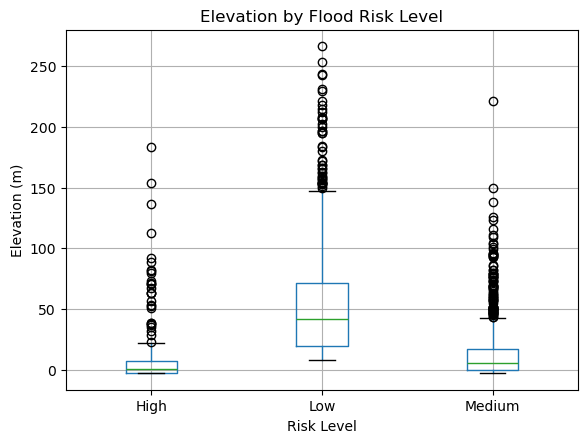

In [30]:
import matplotlib.pyplot as plt

df2.boxplot(
    column="elevation_m",
    by="risk_level"
)

plt.title("Elevation by Flood Risk Level")
plt.suptitle("")
plt.xlabel("Risk Level")
plt.ylabel("Elevation (m)")
plt.show()

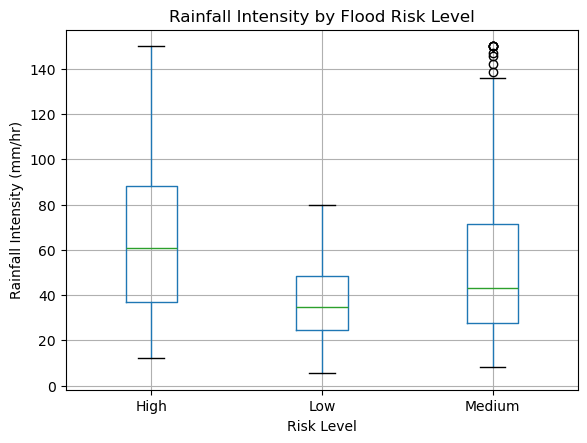

In [31]:
df2.boxplot(
    column="historical_rainfall_intensity_mm_hr",
    by="risk_level"
)

plt.title("Rainfall Intensity by Flood Risk Level")
plt.suptitle("")
plt.xlabel("Risk Level")
plt.ylabel("Rainfall Intensity (mm/hr)")
plt.show()

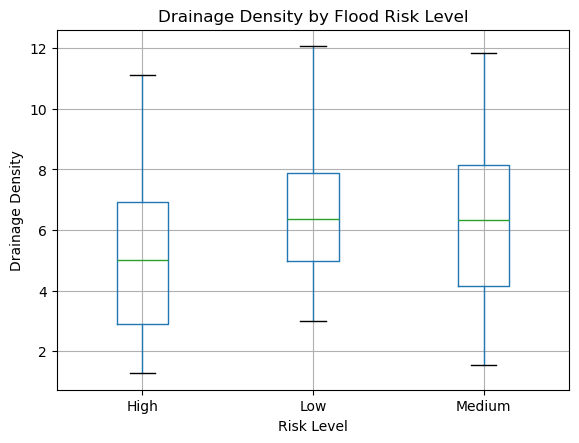

In [32]:
df2.boxplot(
    column="drainage_density_km_per_km2",
    by="risk_level"
)

plt.title("Drainage Density by Flood Risk Level")
plt.suptitle("")
plt.xlabel("Risk Level")
plt.ylabel("Drainage Density")
plt.show()

In [33]:
df2.groupby("risk_level")["risk_labels"].apply(
    lambda x: x.value_counts().head(10)
)

risk_level                                                                
High        ponding_hotspot|low_lying                                           78
            ponding_hotspot|extreme_rain_history|low_lying                      39
            low_lying|sparse_drainage                                           21
            extreme_rain_history|low_lying                                      11
            ponding_hotspot|extreme_rain_history                                 8
            ponding_hotspot|low_lying|sparse_drainage                            6
            extreme_rain_history|sparse_drainage                                 6
            ponding_hotspot|extreme_rain_history|low_lying|sparse_drainage       2
            ponding_hotspot|low_lying|event_2022-12-18                           2
            low_lying|event_2025-06-02                                           2
Low         monitor                                                           1991
Medium      

In [34]:
def assign_risk(label):
    if label == "monitor":
        return "Low"
    
    if "ponding_hotspot" in label:
        return "High"
    
    factors = label.split("|")
    
    if len(factors) >= 2:
        return "High"
    
    return "Medium"

df2["risk_level"] = df2["risk_labels"].apply(assign_risk)

In [35]:
features = [
    "latitude",
    "longitude",
    "elevation_m",
    "land_use",
    "soil_group",
    "drainage_density_km_per_km2",
    "storm_drain_proximity_m",
    "storm_drain_type",
    "historical_rainfall_intensity_mm_hr",
    "return_period_years"
]

X = df2[features]
y = df2["risk_level"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

X shape: (2963, 10)
y shape: (2963,)

Features:
['latitude', 'longitude', 'elevation_m', 'land_use', 'soil_group', 'drainage_density_km_per_km2', 'storm_drain_proximity_m', 'storm_drain_type', 'historical_rainfall_intensity_mm_hr', 'return_period_years']

Target distribution:
risk_level
Low       1991
Medium     611
High       361
Name: count, dtype: int64


In [36]:
X.isnull().sum()

latitude                                 0
longitude                                0
elevation_m                            161
land_use                                 0
soil_group                             362
drainage_density_km_per_km2            284
storm_drain_proximity_m                239
storm_drain_type                       178
historical_rainfall_intensity_mm_hr      0
return_period_years                      0
dtype: int64

In [37]:
print("Soil groups:")
print(X["soil_group"].value_counts())

print("\nStorm drain types:")
print(X["storm_drain_type"].value_counts())

Soil groups:
soil_group
B    747
C    713
D    594
A    547
Name: count, dtype: int64

Storm drain types:
storm_drain_type
CurbInlet      843
Manhole        749
GratedInlet    644
OpenChannel    549
Name: count, dtype: int64


In [38]:
numerical_features = [
    "latitude",
    "longitude",
    "elevation_m",
    "drainage_density_km_per_km2",
    "storm_drain_proximity_m",
    "historical_rainfall_intensity_mm_hr",
    "return_period_years"
]

categorical_features = [
    "land_use",
    "soil_group",
    "storm_drain_type"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['latitude', 'longitude', 'elevation_m', 'drainage_density_km_per_km2', 'storm_drain_proximity_m', 'historical_rainfall_intensity_mm_hr', 'return_period_years']
Categorical features: ['land_use', 'soil_group', 'storm_drain_type']


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (2370, 10)
Testing data: (593, 10)

Training target distribution:
risk_level
Low       1592
Medium     489
High       289
Name: count, dtype: int64

Testing target distribution:
risk_level
Low       399
Medium    122
High       72
Name: count, dtype: int64


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [41]:
numerical_features = [
    'latitude',
    'longitude',
    'elevation_m',
    'drainage_density_km_per_km2',
    'storm_drain_proximity_m',
    'historical_rainfall_intensity_mm_hr',
    'return_period_years'
]

categorical_features = [
    'land_use',
    'soil_group',
    'storm_drain_type'
]

In [42]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [43]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [44]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (2370, 10)
Processed training shape: (2370, 26)
Original testing shape: (593, 10)
Processed testing shape: (593, 26)


In [45]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

print("\nRandom Forest model trained successfully!")


Random Forest model trained successfully!


In [46]:
# Make predictions on test data
y_pred = model.predict(X_test_processed)

print("\nPredictions made successfully!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])


Predictions made successfully!

First 10 actual values:
['Low' 'High' 'Low' 'Medium' 'High' 'High' 'Low' 'Low' 'Low' 'Low']

First 10 predicted values:
['Low' 'Medium' 'Low' 'Medium' 'High' 'High' 'Low' 'Low' 'Low' 'Low']


In [47]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)


Model Accuracy: 0.954468802698145
Model Accuracy (%): 95.4468802698145


In [48]:
from sklearn.metrics import classification_report

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

        High       0.87      0.74      0.80        72
         Low       1.00      1.00      1.00       399
      Medium       0.86      0.93      0.90       122

    accuracy                           0.95       593
   macro avg       0.91      0.89      0.90       593
weighted avg       0.95      0.95      0.95       593




Confusion Matrix:
[[399   0   0]
 [  0 114   8]
 [  1  18  53]]


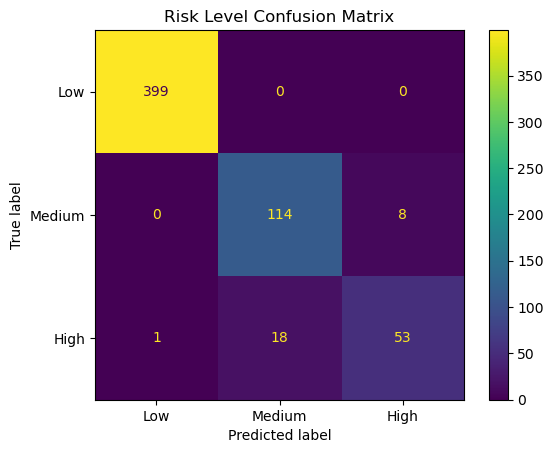

In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Low', 'Medium', 'High']
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot()
plt.title("Risk Level Confusion Matrix")
plt.show()

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (2370, 10)
Testing data: (593, 10)

Training target distribution:
risk_level
Low       1592
Medium     489
High       289
Name: count, dtype: int64

Testing target distribution:
risk_level
Low       399
Medium    122
High       72
Name: count, dtype: int64


In [51]:
print(df2.shape)
print(X.shape)
print(y.shape)
print(X.columns.tolist())
print(y.value_counts())

(2963, 19)
(2963, 10)
(2963,)
['latitude', 'longitude', 'elevation_m', 'land_use', 'soil_group', 'drainage_density_km_per_km2', 'storm_drain_proximity_m', 'storm_drain_type', 'historical_rainfall_intensity_mm_hr', 'return_period_years']
risk_level
Low       1991
Medium     611
High       361
Name: count, dtype: int64


In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (2370, 10)
Testing data: (593, 10)

Training target distribution:
risk_level
Low       1592
Medium     489
High       289
Name: count, dtype: int64

Testing target distribution:
risk_level
Low       399
Medium    122
High       72
Name: count, dtype: int64


In [53]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original features:", X_train.shape[1])
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Original features: 10
Processed training shape: (2370, 26)
Processed testing shape: (593, 26)


In [55]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [56]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Make predictions
y_pred_rf = rf_model.predict(X_test_processed)

# Accuracy
accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.9527824620573356

Classification Report:
              precision    recall  f1-score   support

        High       0.89      0.71      0.79        72
         Low       1.00      1.00      1.00       399
      Medium       0.85      0.95      0.90       122

    accuracy                           0.95       593
   macro avg       0.91      0.89      0.89       593
weighted avg       0.95      0.95      0.95       593


Confusion Matrix:
[[ 51   1  20]
 [  0 398   1]
 [  6   0 116]]


In [57]:
import xgboost

print("XGBoost version:", xgboost.__version__)

ModuleNotFoundError: No module named 'xgboost'

In [59]:
conda install -c conda-forge xgboost

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.1.1
    latest version: 26.9.1

Please update conda by running

    $ conda update -n base -c defaults conda



# All requested packages already installed.


Note: you may need to restart the kernel to use updated packages.


In [61]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.0


In [72]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric="mlogloss"
)

xgb_model.fit(X_train_processed, y_train)

print("XGBoost training completed!")

ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1 2], got ['High' 'Low' 'Medium']

In [63]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)
y_test_xgb = label_encoder.transform(y_test)

print("Class mapping:")
for i, class_name in enumerate(label_encoder.classes_):
    print(i, "=", class_name)

Class mapping:
0 = High
1 = Low
2 = Medium


In [92]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric="mlogloss"
)

xgb_model.fit(X_train_processed, y_train_xgb)

print("XGBoost training completed!")

XGBoost training completed!


In [89]:
y = df2["risk_level"]

In [93]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict using XGBoost
y_pred_xgb_encoded = xgb_model.predict(X_test_processed)

# Convert numerical predictions back to Low/Medium/High
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded.astype(int)
)

# Accuracy
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", xgb_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

XGBoost Accuracy: 0.9713322091062394

Classification Report:
              precision    recall  f1-score   support

        High       0.92      0.85      0.88        72
         Low       1.00      1.00      1.00       399
      Medium       0.91      0.96      0.94       122

    accuracy                           0.97       593
   macro avg       0.95      0.93      0.94       593
weighted avg       0.97      0.97      0.97       593


Confusion Matrix:
[[ 61   1  10]
 [  0 398   1]
 [  5   0 117]]


In [94]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print(feature_names)

Number of processed features: 26
['num__latitude' 'num__longitude' 'num__elevation_m'
 'num__drainage_density_km_per_km2' 'num__storm_drain_proximity_m'
 'num__historical_rainfall_intensity_mm_hr' 'num__return_period_years'
 'cat__land_use_Commercial' 'cat__land_use_Green'
 'cat__land_use_Industrial' 'cat__land_use_Informal'
 'cat__land_use_Institutional' 'cat__land_use_Mixed'
 'cat__land_use_Residential' 'cat__land_use_Roads' 'cat__land_use_Water'
 'cat__soil_group_A' 'cat__soil_group_B' 'cat__soil_group_C'
 'cat__soil_group_D' 'cat__soil_group_nan'
 'cat__storm_drain_type_CurbInlet' 'cat__storm_drain_type_GratedInlet'
 'cat__storm_drain_type_Manhole' 'cat__storm_drain_type_OpenChannel'
 'cat__storm_drain_type_nan']


In [70]:
import pandas as pd

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

                                     Feature  Importance
2                           num__elevation_m    0.262788
3           num__drainage_density_km_per_km2    0.152327
5   num__historical_rainfall_intensity_mm_hr    0.150944
19                         cat__soil_group_D    0.076518
18                         cat__soil_group_C    0.053777
16                         cat__soil_group_A    0.049553
22         cat__storm_drain_type_GratedInlet    0.030753
17                         cat__soil_group_B    0.026716
15                       cat__land_use_Water    0.020598
8                        cat__land_use_Green    0.019738
11               cat__land_use_Institutional    0.016913
4               num__storm_drain_proximity_m    0.016038
1                             num__longitude    0.014877
21           cat__storm_drain_type_CurbInlet    0.013636
0                              num__latitude    0.013171
6                   num__return_period_years    0.012564
9                   cat__land_u

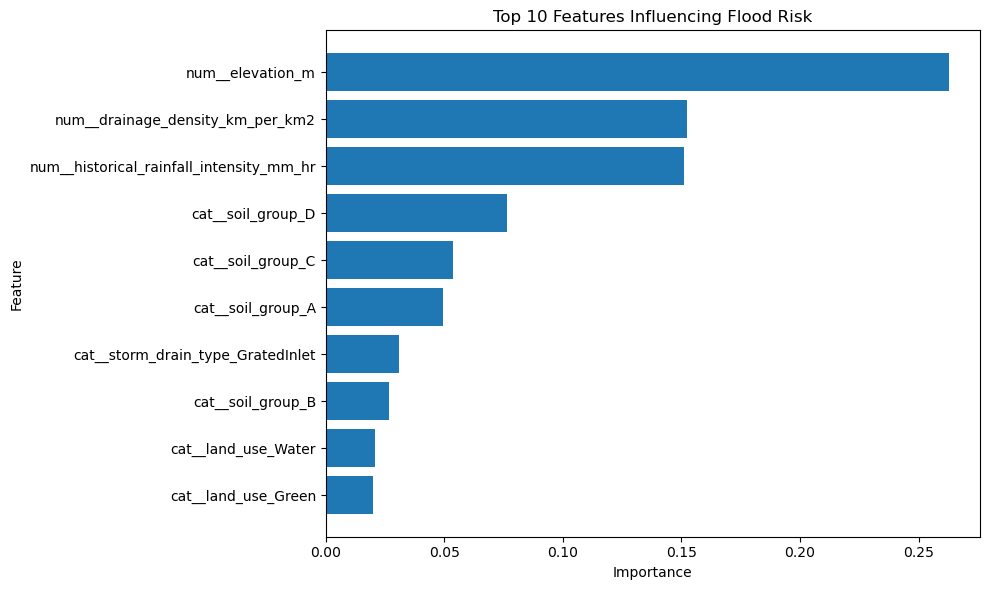

In [71]:
import matplotlib.pyplot as plt

top_features = importance_df.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing Flood Risk")

plt.tight_layout()
plt.show()

In [73]:
print(type(xgb_model))

<class 'xgboost.sklearn.XGBClassifier'>


In [74]:
print(type(preprocessor))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>


In [75]:
import joblib

# Save XGBoost model
joblib.dump(xgb_model, "xgboost_flood_model.pkl")

# Save preprocessing pipeline
joblib.dump(preprocessor, "flood_preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [76]:
import os

print("Model exists:", os.path.exists("xgboost_flood_model.pkl"))
print("Preprocessor exists:", os.path.exists("flood_preprocessor.pkl"))

Model exists: True
Preprocessor exists: True


In [83]:
new_location = pd.DataFrame({
    "latitude": [12.97],
    "longitude": [77.59],
    "elevation_m": [8.0],
    "land_use": ["Residential"],
    "soil_group": ["C"],
    "drainage_density_km_per_km2": [5.0],
    "storm_drain_proximity_m": [120.0],
    "storm_drain_type": ["CurbInlet"],
    "historical_rainfall_intensity_mm_hr": [65.0],
    "return_period_years": [25.0]
})

new_location

,latitude,longitude,elevation_m,land_use,soil_group,drainage_density_km_per_km2,storm_drain_proximity_m,storm_drain_type,historical_rainfall_intensity_mm_hr,return_period_years
0,12.97,77.59,8.0,Residential,C,5.0,120.0,CurbInlet,65.0,25.0


In [78]:
new_location_processed = preprocessor.transform(new_location)

print("Processed shape:", new_location_processed.shape)

Processed shape: (1, 26)


In [79]:
prediction = xgb_model.predict(new_location_processed)

print("Predicted Risk:", prediction[0])

NotFittedError: need to call fit or load_model beforehand

In [80]:
import joblib

xgb_model = joblib.load("xgboost_flood_model.pkl")
preprocessor = joblib.load("flood_preprocessor.pkl")

print("Model and preprocessor loaded successfully!")

Model and preprocessor loaded successfully!


In [81]:
print(type(xgb_model))
print(type(preprocessor))

<class 'xgboost.sklearn.XGBClassifier'>
<class 'sklearn.compose._column_transformer.ColumnTransformer'>


In [84]:
new_location_processed = preprocessor.transform(new_location)

prediction = xgb_model.predict(new_location_processed)

print("Predicted Risk:", prediction[0])

NotFittedError: need to call fit or load_model beforehand

In [85]:
import os

print("Model file exists:", os.path.exists("xgboost_flood_model.pkl"))
print("Preprocessor file exists:", os.path.exists("flood_preprocessor.pkl"))

Model file exists: True
Preprocessor file exists: True


In [86]:
import joblib

loaded_model = joblib.load("xgboost_flood_model.pkl")

print(type(loaded_model))
print("Has booster:", loaded_model.get_booster())

<class 'xgboost.sklearn.XGBClassifier'>


NotFittedError: need to call fit or load_model beforehand

In [95]:
print(xgb_model.get_booster())

In [96]:
xgb_predictions = xgb_model.predict(X_test_processed)

from sklearn.metrics import accuracy_score

print("XGBoost Accuracy:", accuracy_score(y_test, xgb_predictions))

XGBoost Accuracy: 0.0


In [97]:
print("Actual labels:")
print(y_test.unique())

print("\nPredicted labels:")
print(xgb_predictions[:20])

print("\nPrediction type:")
print(type(xgb_predictions[0]))

Actual labels:
['Low' 'High' 'Medium']

Predicted labels:
[1 0 1 2 0 0 1 1 1 1 2 1 1 1 1 1 1 1 1 1]

Prediction type:
<class 'numpy.int64'>


In [98]:
print("Actual label counts:")
print(y_test.value_counts())

print("\nPredicted label counts:")
print(pd.Series(xgb_predictions).value_counts())

Actual label counts:
risk_level
Low       399
Medium    122
High       72
Name: count, dtype: int64

Predicted label counts:
1    399
2    128
0     66
Name: count, dtype: int64


In [99]:
print(xgb_model.classes_)

[0 1 2]


In [100]:
print(xgb_model.classes_)


[0 1 2]


In [101]:
print(label_encoder.classes_)

['High' 'Low' 'Medium']


In [102]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

In [103]:
print(type(y_train))
print(y_train.head())

<class 'pandas.core.series.Series'>
1172       Low
1686       Low
937        Low
1444    Medium
856        Low
Name: risk_level, dtype: object


In [104]:
xgb_predictions_labels = label_encoder.inverse_transform(xgb_predictions)

print(xgb_predictions_labels[:20])

['Low' 'High' 'Low' 'Medium' 'High' 'High' 'Low' 'Low' 'Low' 'Low'
 'Medium' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low' 'Low']


In [105]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, xgb_predictions_labels)

print("XGBoost Accuracy:", accuracy)
print("XGBoost Accuracy (%):", accuracy * 100)

XGBoost Accuracy: 0.9713322091062394
XGBoost Accuracy (%): 97.13322091062395


In [106]:
from sklearn.metrics import classification_report

print(classification_report(y_test, xgb_predictions_labels))

              precision    recall  f1-score   support

        High       0.92      0.85      0.88        72
         Low       1.00      1.00      1.00       399
      Medium       0.91      0.96      0.94       122

    accuracy                           0.97       593
   macro avg       0.95      0.93      0.94       593
weighted avg       0.97      0.97      0.97       593



In [107]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    xgb_predictions_labels,
    labels=["High", "Low", "Medium"]
)

print(cm)

[[ 61   1  10]
 [  0 398   1]
 [  5   0 117]]


In [108]:
import joblib

joblib.dump(xgb_model, "xgboost_flood_model.pkl")
joblib.dump(preprocessor, "flood_preprocessor.pkl")

print("Fitted model and preprocessor saved successfully!")

Fitted model and preprocessor saved successfully!


In [109]:
loaded_model = joblib.load("xgboost_flood_model.pkl")

print("Model type:", type(loaded_model))
print("Model is fitted:", loaded_model.get_booster())

Model type: <class 'xgboost.sklearn.XGBClassifier'>
Model is fitted: <xgboost.core.Booster object at 0x309c6f5c0>


In [110]:
import pandas as pd

new_location = pd.DataFrame({
    "latitude": [12.97],
    "longitude": [77.59],
    "elevation_m": [8.0],
    "land_use": ["Residential"],
    "soil_group": ["C"],
    "drainage_density_km_per_km2": [5.0],
    "storm_drain_proximity_m": [120.0],
    "storm_drain_type": ["CurbInlet"],
    "historical_rainfall_intensity_mm_hr": [65.0],
    "return_period_years": [25.0]
})

print(new_location)

   latitude  longitude  elevation_m     land_use soil_group  \
0     12.97      77.59          8.0  Residential          C   

   drainage_density_km_per_km2  storm_drain_proximity_m storm_drain_type  \
0                          5.0                    120.0        CurbInlet   

   historical_rainfall_intensity_mm_hr  return_period_years  
0                                 65.0                 25.0  


In [111]:
import joblib

loaded_model = joblib.load("xgboost_flood_model.pkl")
loaded_preprocessor = joblib.load("flood_preprocessor.pkl")

print("Model and preprocessor loaded!")

Model and preprocessor loaded!


In [112]:
new_location_processed = loaded_preprocessor.transform(new_location)

print("Processed shape:", new_location_processed.shape)

Processed shape: (1, 26)


In [113]:
prediction_encoded = loaded_model.predict(new_location_processed)

print("Encoded prediction:", prediction_encoded)

Encoded prediction: [2]


In [114]:
prediction_label = label_encoder.inverse_transform(prediction_encoded)

print("Predicted Flood Risk:", prediction_label[0])

Predicted Flood Risk: Medium


In [115]:
probabilities = loaded_model.predict_proba(new_location_processed)

print("Prediction probabilities:")

for label, probability in zip(
    label_encoder.classes_,
    probabilities[0]
):
    print(f"{label}: {probability:.2%}")

Prediction probabilities:
High: 5.59%
Low: 18.60%
Medium: 75.81%
